In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
import random
from matplotlib.colors import ListedColormap
import pandas as pd 

In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import os
from PIL import Image
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [4]:
ruta = "dt_lab7/gogogo/CIFAR-10-images-master/train"
LADO = 32 

rutas = []
for carpeta, _, archivos in os.walk(ruta):
    for archivo in archivos:
        if archivo.lower().endswith((".png", ".jpg", ".jpeg")):
            rutas.append(os.path.join(carpeta, archivo))
print(len(rutas), "imágenes encontradas")

rng = np.random.default_rng(42)
rng.shuffle(rutas)

def cargar(r):
    img = Image.open(r).convert("RGB").resize((LADO, LADO))
    return np.asarray(img, dtype=np.float32).ravel()

df_emnist = pd.DataFrame([cargar(r) for r in rutas])
print(df_emnist.shape)
df_emnist.head()

50000 imágenes encontradas
(50000, 3072)


,0,1,2,3,4,5,6,7,8,9,...,3062,3063,3064,3065,3066,3067,3068,3069,3070,3071
0,154.0,169.0,192.0,154.0,169.0,192.0,154.0,169.0,192.0,154.0,...,160.0,78.0,114.0,166.0,83.0,109.0,168.0,82.0,103.0,166.0
1,93.0,109.0,60.0,96.0,112.0,63.0,93.0,106.0,60.0,86.0,...,78.0,117.0,127.0,75.0,115.0,128.0,75.0,125.0,138.0,85.0
2,84.0,75.0,66.0,90.0,81.0,72.0,106.0,97.0,90.0,124.0,...,161.0,192.0,178.0,169.0,180.0,166.0,157.0,185.0,171.0,162.0
3,109.0,119.0,32.0,107.0,117.0,28.0,108.0,119.0,25.0,111.0,...,82.0,106.0,104.0,63.0,125.0,130.0,66.0,126.0,134.0,57.0
4,28.0,37.0,32.0,35.0,44.0,39.0,40.0,46.0,42.0,36.0,...,142.0,174.0,163.0,145.0,176.0,165.0,147.0,175.0,164.0,146.0


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test = train_test_split(df_emnist, random_state=42)  
X_test = X_test[:40]
print(X_train.shape, X_test.shape)

(37500, 3072) (40, 3072)


In [6]:
X_train = X_train.astype(np.float64) / 255.0
X_test = X_test.astype(np.float64) / 255.0

In [6]:
X = X_train.values 
kmeans_per_k = [KMeans(n_clusters=k, random_state=42).fit(X) for k in range(1, 10)]
silhouette_scores = [silhouette_score(X, model.labels_) for model in kmeans_per_k[1:]]

max_k = 20 # no más de los centros generados
kmeans_per_k = [KMeans(n_clusters=k, random_state=42).fit(X) for k in range(1, max_k + 1)]
silhouette_scores = [silhouette_score(X, model.labels_) for model in kmeans_per_k[1:]]
# Generar eje x para k de 2 hasta max_k
ks = list(range(2, max_k + 1))

# plt.figure(figsize=(8, 3))
# plt.plot(ks, silhouette_scores, "bo-")
# # plt.plot(range(2, 10), silhouette_scores, "bo-")
# plt.xlabel("$k$", fontsize=14)
# plt.ylabel("Silhouette score", fontsize=14)
# plt.axis([1.8, 8.5, 0.55, 0.7])
# plt.show()

plt.figure(figsize=(8, 3))
plt.plot(ks, silhouette_scores, "bo-")
plt.xlabel("$k$", fontsize=14)
plt.ylabel("Silhouette score", fontsize=14)
plt.title("Silhouette Score vs Número de Clusters", fontsize=14)
plt.grid(True)
plt.show()

: 

: 

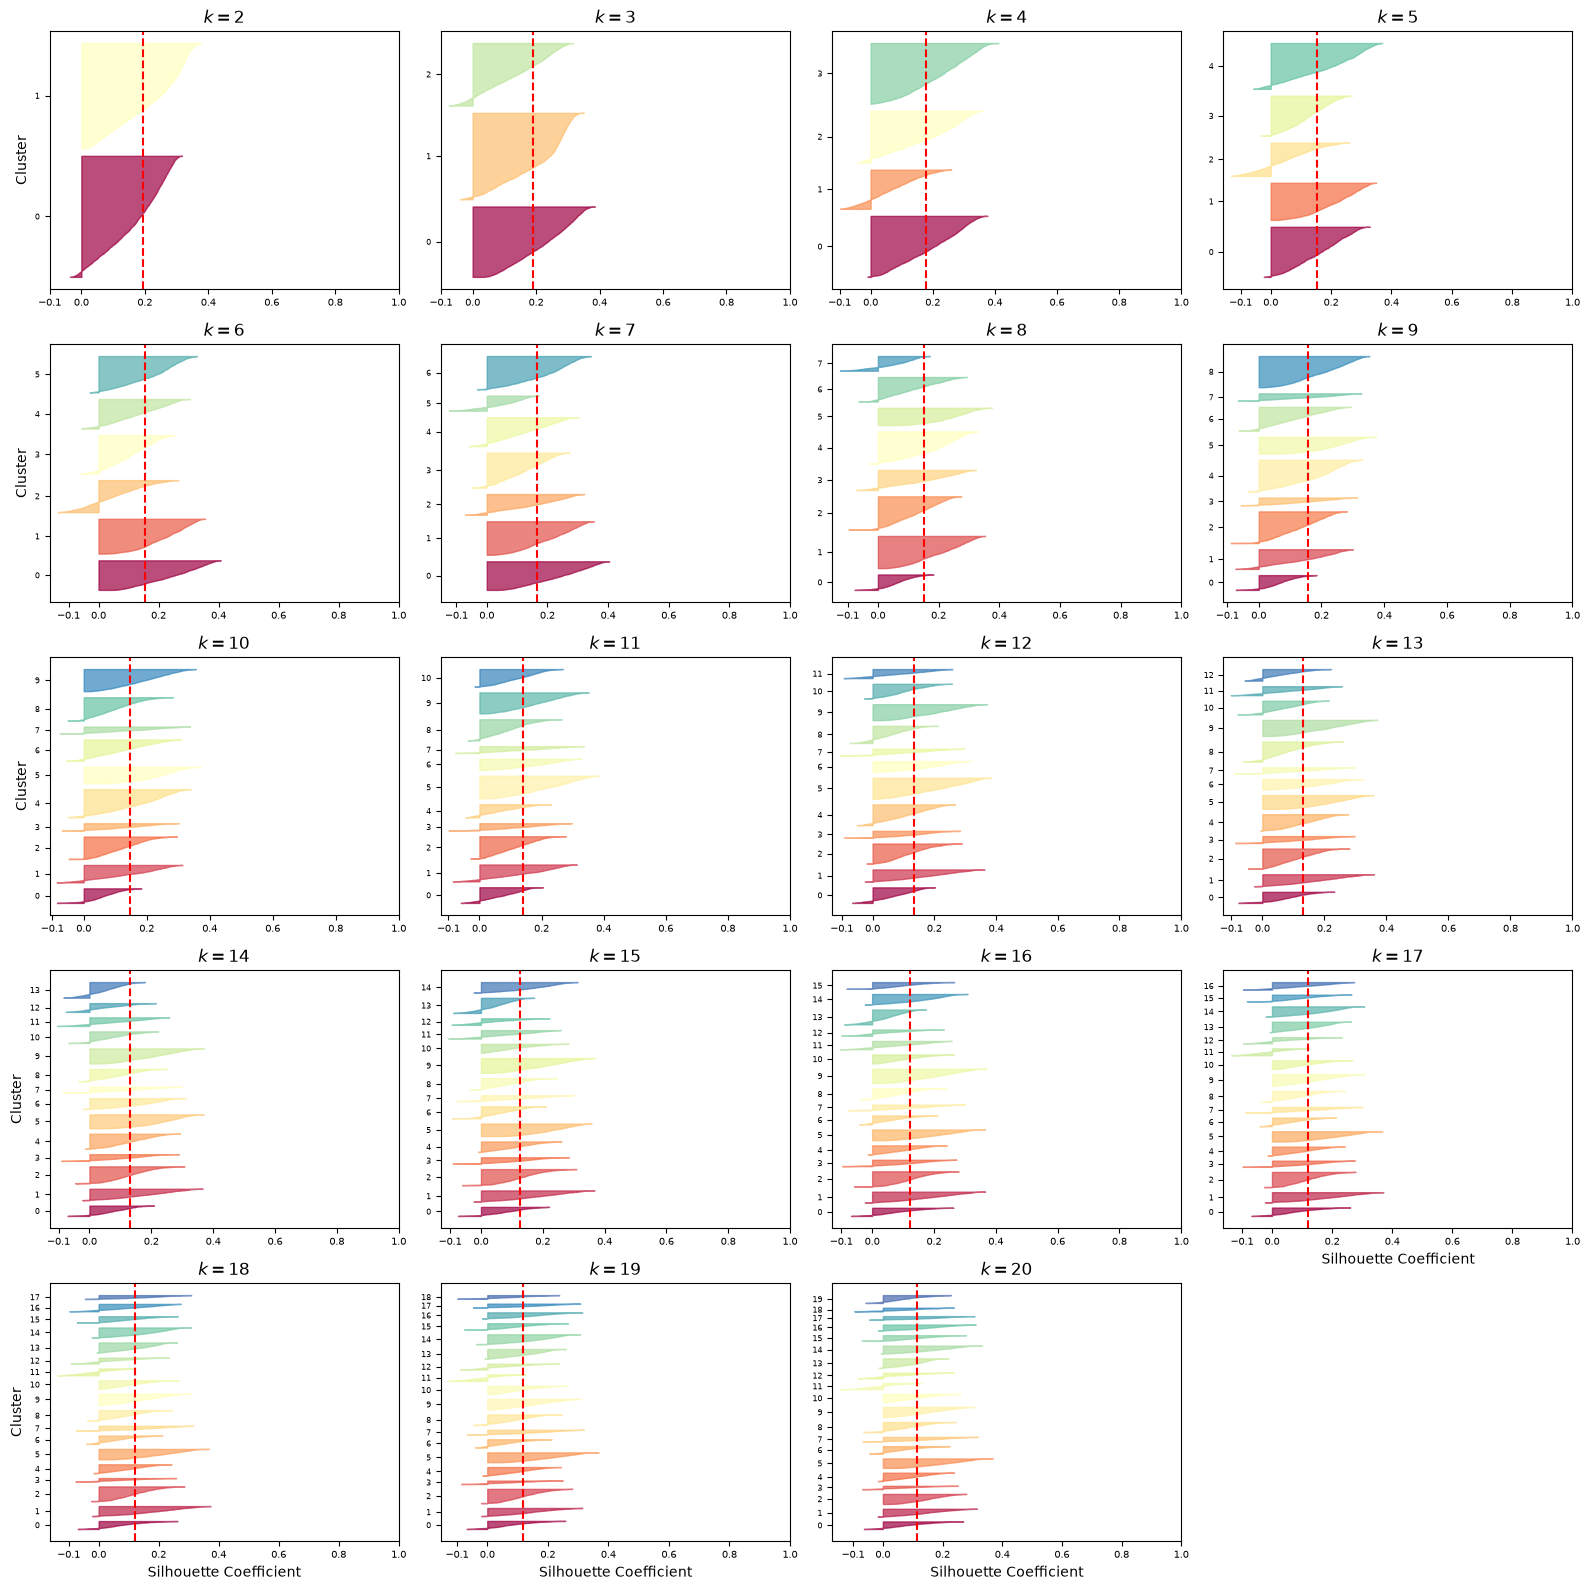

In [7]:
from sklearn.metrics import silhouette_samples
from matplotlib.ticker import FixedLocator, FixedFormatter
import matplotlib as mpl

valid_ks = ks                                   # <-- CAMBIO: todos los k (2, 3, ..., max_k)
n_cols = 4                                      # <-- NUEVO: 4 gráficos por fila
n_rows = int(np.ceil(len(valid_ks) / n_cols))   # <-- NUEVO: filas necesarias

plt.figure(figsize=(4 * n_cols, 3.2 * n_rows))  # <-- CAMBIO: el tamaño crece con la cantidad de gráficos

for plot_idx, k in enumerate(valid_ks):
    plt.subplot(n_rows, n_cols, plot_idx + 1)   # <-- CAMBIO: cuadrícula dinámica (antes 2, 2)

    y_pred = kmeans_per_k[k - 1].labels_
    silhouette_coefficients = silhouette_samples(X, y_pred)

    padding = len(X) // 30
    pos = padding
    ticks = []
    for i in range(k):
        coeffs = silhouette_coefficients[y_pred == i]
        coeffs.sort()

        color = mpl.cm.Spectral(i / k)
        plt.fill_betweenx(np.arange(pos, pos + len(coeffs)), 0, coeffs,
                          facecolor=color, edgecolor=color, alpha=0.7)
        ticks.append(pos + len(coeffs) // 2)
        pos += len(coeffs) + padding

    plt.gca().yaxis.set_major_locator(FixedLocator(ticks))
    plt.gca().yaxis.set_major_formatter(FixedFormatter(range(k)))
    plt.tick_params(axis='y', labelsize=6)                          # <-- NUEVO: números de cluster pequeños para que quepan

    if plot_idx % n_cols == 0:                                      # <-- CAMBIO: etiqueta "Cluster" en la primera columna
        plt.ylabel("Cluster")

    plt.gca().set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])         # <-- CAMBIO: se muestra siempre (antes dependía de k in (3,4,5,6))
    plt.tick_params(axis='x', labelsize=7)
    if plot_idx >= len(valid_ks) - n_cols:                          # <-- CAMBIO: etiqueta x solo en la última fila
        plt.xlabel("Silhouette Coefficient")

    plt.axvline(x=silhouette_scores[k - 2], color="red", linestyle="--")
    plt.title("$k={}$".format(k), fontsize=12)

plt.tight_layout()                                                  # <-- NUEVO: evita que se solapen los títulos
plt.show()

In [7]:
from sklearn.cluster import KMeans

k = 20
kmeans = KMeans(n_clusters=k, random_state=42)
X_digits_dist = kmeans.fit_transform(X_train)

print(X_digits_dist.shape)

(37500, 20)


In [8]:
print(X_digits_dist.shape)
print(X_digits_dist)

(37500, 20)
[[30.3228348  25.72835185 20.5880915  ... 23.67918915 29.92810555
  25.64274715]
 [12.84091632 11.1734041  11.13185513 ...  9.30040722 13.79857668
  12.72275804]
 [12.73179412 13.68484182 16.71699241 ... 14.8140544  12.4829392
  16.4230184 ]
 ...
 [11.48846111 12.11317546 14.02295292 ... 10.80801936 13.59685935
  13.60374047]
 [22.03832176 18.58027563 14.02739593 ... 16.36276221 20.47482025
  17.27899999]
 [14.30548804 12.54546523 12.52828441 ... 13.45375127 11.40460086
  12.0177663 ]]


In [9]:
idxs = np.argmin(X_digits_dist, axis=0)
X_representative_digits = X_train.values[idxs]

In [10]:
print(X_representative_digits.shape)
print(X_representative_digits)

(20, 3072)
[[0.54901961 0.52941176 0.45490196 ... 0.3254902  0.32941176 0.20392157]
 [0.36862745 0.38431373 0.23921569 ... 0.36470588 0.39215686 0.25882353]
 [0.50196078 0.50980392 0.45882353 ... 0.56862745 0.55686275 0.52156863]
 ...
 [0.59607843 0.5254902  0.47843137 ... 0.60784314 0.54117647 0.4627451 ]
 [0.45490196 0.54901961 0.4627451  ... 0.23137255 0.30588235 0.21960784]
 [0.61176471 0.67058824 0.58039216 ... 0.41176471 0.44313725 0.39215686]]


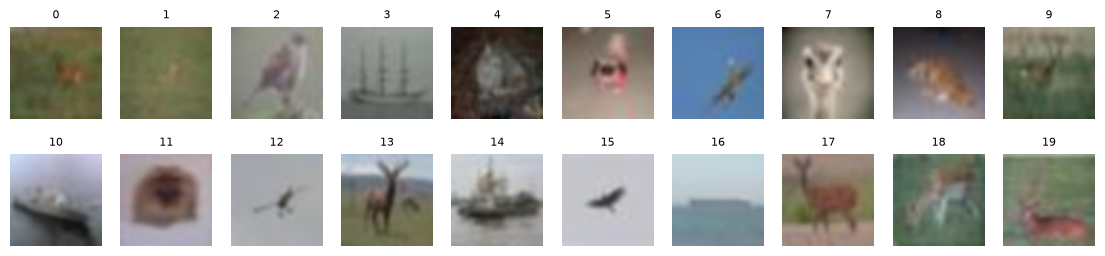

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 8))
for index, X_representative_digit in enumerate(X_representative_digits):
  plt.subplot(5, 10, index+1)
  plt.imshow(X_representative_digit.reshape(32, 32, 3), interpolation="bicubic")
  plt.title(index, fontsize=8)
  plt.axis('off')
plt.show()

In [29]:
y_representative_digits = np.array([
    "deer", "frog", "bird", "ship", "cat", "frog", "airplane", "bird", "cat", "deer", "ship", "dog", "airplane", "deer", "ship", "bird", "ship", "deer", "deer", "deer"])
print(len(y_representative_digits))

20


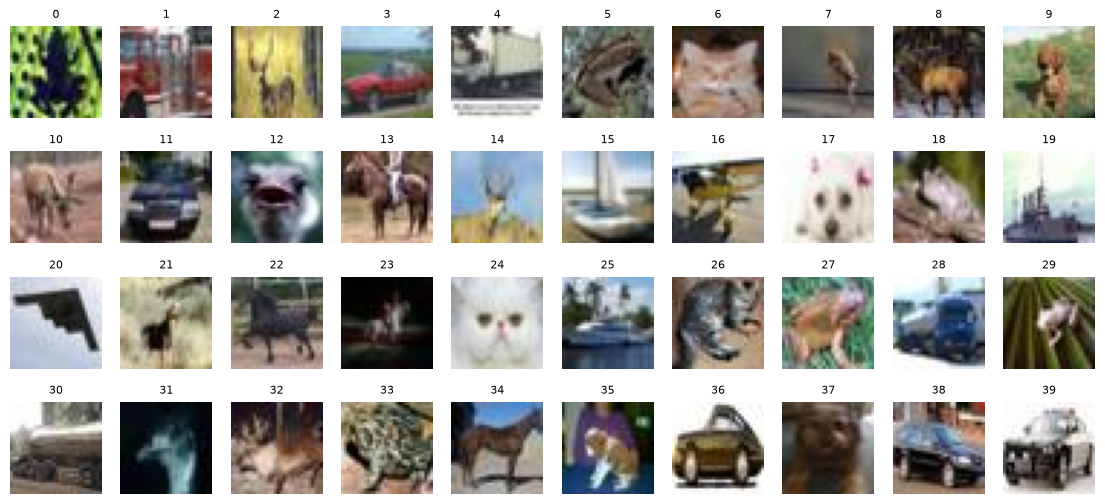

In [20]:
plt.figure(figsize=(14, 16))
for index, img in enumerate(X_test.values):
  plt.subplot(10, 10, index+1)
  plt.imshow(img.reshape(32, 32, 3))
  plt.title(index, fontsize=8)
  plt.axis('off')
plt.show()

In [27]:
y_test = np.array([
    "frog", "automobile", "deer", "automobile", "truck", "bird", "cat", "bird", "deer", "dog", "deer", "automobile", "bird", "horse", "deer", "ship", "airplane", "dog", "cat", "ship", "airplane", "bird", "horse", "horse", "cat", "ship", "cat", "frog", "truck", "frog", "truck", "bird", "deer", "frog", "horse", "dog", "automobile", "dog", "automobile", "automobile"])
print(len(y_test))

40


In [30]:
from sklearn.linear_model import LogisticRegression

log_reg2 = LogisticRegression(solver="lbfgs", max_iter=5000, random_state=42)
%time log_reg2.fit(X_representative_digits, y_representative_digits)
log_reg2.score(X_test, y_test)

CPU times: total: 2.7 s
Wall time: 2.33 s


0.1

In [31]:
y_train_propagated = np.empty(len(X_train), dtype=object)    # <-- CAMBIO: admite texto
for i in range(k):
  y_train_propagated[kmeans.labels_==i] = y_representative_digits[i]

In [32]:
log_reg3 = LogisticRegression(solver="lbfgs", max_iter=5000, random_state=42)
%time log_reg3.fit(X_train[:1000], y_train_propagated[:1000])
log_reg3.score(X_test, y_test)

CPU times: total: 2min 10s
Wall time: 16.4 s


0.125

In [33]:
for digito in np.unique(y_representative_digits):
    grupos = np.where(y_representative_digits == digito)[0]
    print(f"Dígito {digito}: grupos {grupos}")

Dígito airplane: grupos [ 6 12]
Dígito bird: grupos [ 2  7 15]
Dígito cat: grupos [4 8]
Dígito deer: grupos [ 0  9 13 17 18 19]
Dígito dog: grupos [11]
Dígito frog: grupos [1 5]
Dígito ship: grupos [ 3 10 14 16]


In [34]:
pred2 = log_reg2.predict(X_test)
pred3 = log_reg3.predict(X_test)

print("Imágenes donde predicen distinto:", (pred2 != pred3).sum(), "de", len(y_test))
print("Aciertos log_reg2:", (pred2 == y_test).sum(), "| log_reg3:", (pred3 == y_test).sum())

print("Etiquetas distintas en las 1000 de entrenamiento:", np.unique(y_train_propagated[:1000], return_counts=True))
print("Etiquetas distintas en las representativas:", np.unique(y_representative_digits, return_counts=True))

Imágenes donde predicen distinto: 8 de 40
Aciertos log_reg2: 4 | log_reg3: 5
Etiquetas distintas en las 1000 de entrenamiento: (array([np.str_('airplane'), np.str_('bird'), np.str_('cat'),
       np.str_('deer'), np.str_('dog'), np.str_('frog'), np.str_('ship')],
      dtype=object), array([ 67, 135,  96, 353,  37, 123, 189]))
Etiquetas distintas en las representativas: (array(['airplane', 'bird', 'cat', 'deer', 'dog', 'frog', 'ship'],
      dtype='<U8'), array([2, 3, 2, 6, 1, 2, 4]))


aprendizaje activo

In [35]:
probas = log_reg3.predict_proba(X_train[:1000])
labels_ixs = np.argmax(probas, axis=1)
labels = np.array([proba[ix] for proba, ix in zip(probas, labels_ixs)])
sorted_ixs = np.argsort(labels)
labels[sorted_ixs[:10]]

array([0.43287152, 0.55033902, 0.59746847, 0.6160185 , 0.63871726,
       0.6701517 , 0.67596726, 0.67716695, 0.68876765, 0.69428708])

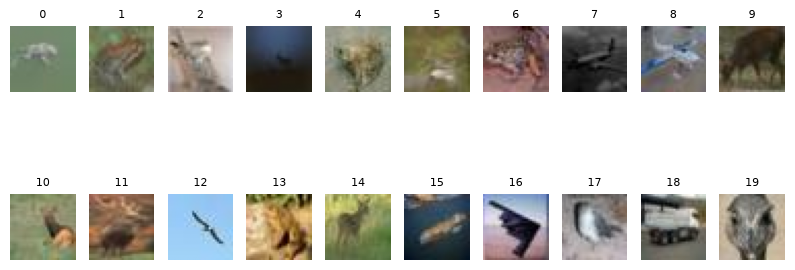

In [36]:
n_consulta = 20                                                  # <-- NUEVO: cuántas imágenes vas a etiquetar por ronda

X_lowest = X_train.values[:1000][sorted_ixs[:n_consulta]]
plt.figure(figsize=(10, 4))
for index, img in enumerate(X_lowest):
    plt.subplot(int(np.ceil(n_consulta / 10)), 10, index + 1)    # <-- CAMBIO: filas calculadas (antes k // 10)
    plt.imshow(img.reshape(32, 32, 3))
    plt.title(index, fontsize=8)                                 # <-- NUEVO: número de cada imagen
    plt.axis('off')
plt.show()

In [37]:
y_lowest = np.array([
    "frog", "frog", "bird", "deer", "frog", "deer", "frog", "airplane", "airplane", "deer", "deer", "deer", "horse", "bird", "deer", "ship", "airplane", "bird", "truck", "bird"
])
assert len(y_lowest) == n_consulta

In [38]:
print(y_train_propagated[:1000][sorted_ixs[:n_consulta]])

[np.str_('frog') np.str_('frog') np.str_('airplane') np.str_('cat')
 np.str_('bird') np.str_('frog') np.str_('frog') np.str_('cat')
 np.str_('ship') np.str_('deer') np.str_('bird') np.str_('frog')
 np.str_('bird') np.str_('deer') np.str_('frog') np.str_('cat')
 np.str_('bird') np.str_('frog') np.str_('frog') np.str_('bird')]


In [39]:
y_train2 = y_train_propagated[:1000].copy()
y_train2[sorted_ixs[:n_consulta]] = y_lowest

In [40]:
log_reg5 = LogisticRegression(solver="lbfgs", max_iter=5000, random_state=42)    # sin multi_class
%time log_reg5.fit(X_train[:1000], y_train2)
log_reg5.score(X_test, y_test)

CPU times: total: 2min 35s
Wall time: 18.7 s


0.125

ronda de correccion numero 2

In [30]:
ya_corregidas = np.zeros(1000, dtype=bool)
ya_corregidas[sorted_ixs[:n_consulta]] = True            # marca las de la ronda 1

probas = log_reg5.predict_proba(X_train[:1000])
labels_ixs = np.argmax(probas, axis=1)
labels = np.array([proba[ix] for proba, ix in zip(probas, labels_ixs)])
labels[ya_corregidas] = 2                                # confianza imposible: quedan al final del orden
sorted_ixs = np.argsort(labels)

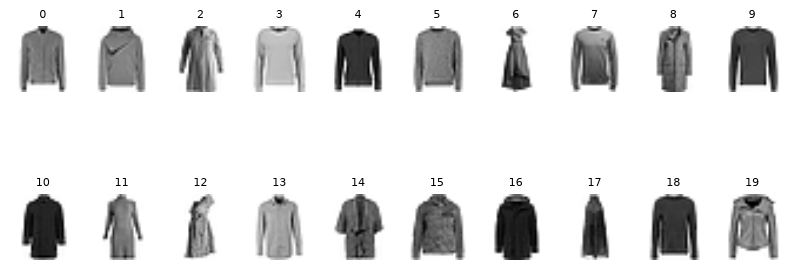

In [ ]:
n_consulta = 20                                                  # <-- NUEVO: cuántas imágenes vas a etiquetar por ronda

X_lowest = X_train.values[:1000][sorted_ixs[:n_consulta]]
plt.figure(figsize=(10, 4))
for index, img in enumerate(X_lowest):
    plt.subplot(int(np.ceil(n_consulta / 10)), 10, index + 1)    # <-- CAMBIO: filas calculadas (antes k // 10)
    plt.imshow(img.reshape(32, 32, 3))
    plt.title(index, fontsize=8)                                 # <-- NUEVO: número de cada imagen
    plt.axis('off')
plt.show()

In [32]:
y_lowest = np.array([
    "abrigo", "abrigo", "abrigo", "jersey", "abrigo", "jersey", "vestido", "jersey", "abrigo", "jersey", "abrigo", "vestido", "abrigo", "camisa", "abrigo", "abrigo", "abrigo", "vestido", "jersey", "abrigo"
])
assert len(y_lowest) == n_consulta

In [33]:
y_train3 = y_train2.copy()                               # parte de lo ya corregido
y_train3[sorted_ixs[:n_consulta]] = y_lowest             # y_lowest = tus nuevas etiquetas
log_reg6 = LogisticRegression(solver="lbfgs", max_iter=5000, random_state=42)
log_reg6.fit(X_train[:1000], y_train3)
log_reg6.score(X_test, y_test)

0.65